## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_validate
)

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

## Load and understand the dataset

In [2]:
df = pd.read_csv("HR-Employee-Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
df.tail()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,...,1,80,0,6,3,4,4,3,1,2


In [4]:
df.shape

(1470, 35)

In [5]:
df.dtypes

Age                         int64
Attrition                     str
BusinessTravel                str
DailyRate                   int64
Department                    str
DistanceFromHome            int64
Education                   int64
EducationField                str
EmployeeCount               int64
EmployeeNumber              int64
EnvironmentSatisfaction     int64
Gender                        str
HourlyRate                  int64
JobInvolvement              int64
JobLevel                    int64
JobRole                       str
JobSatisfaction             int64
MaritalStatus                 str
MonthlyIncome               int64
MonthlyRate                 int64
NumCompaniesWorked          int64
Over18                        str
OverTime                      str
PercentSalaryHike           int64
PerformanceRating           int64
RelationshipSatisfaction    int64
StandardHours               int64
StockOptionLevel            int64
TotalWorkingYears           int64
TrainingTimesL

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [7]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


## Data cleaning

In [8]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.drop(
    columns=[
        "EmployeeNumber",
        "EmployeeCount",
        "StandardHours",
        "Over18"
    ],
    inplace=True,
    errors="ignore"
)

In [11]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSinceLastPromotion     0
YearsWithCurrManager        0
dtype: int64

## Exploratory Data Analysis

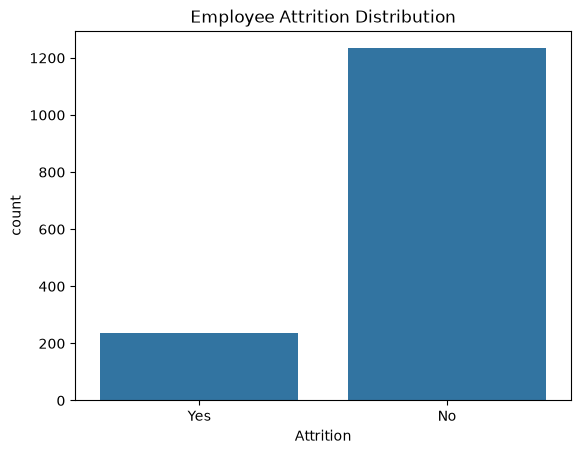

In [12]:
sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition Distribution")
plt.show()

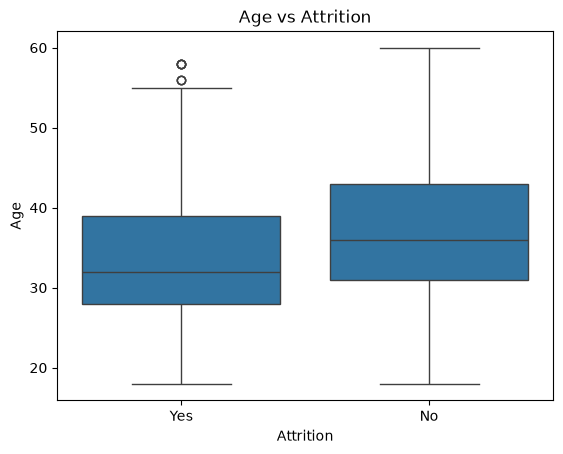

In [13]:
sns.boxplot(data=df, x="Attrition", y="Age")
plt.title("Age vs Attrition")
plt.show()

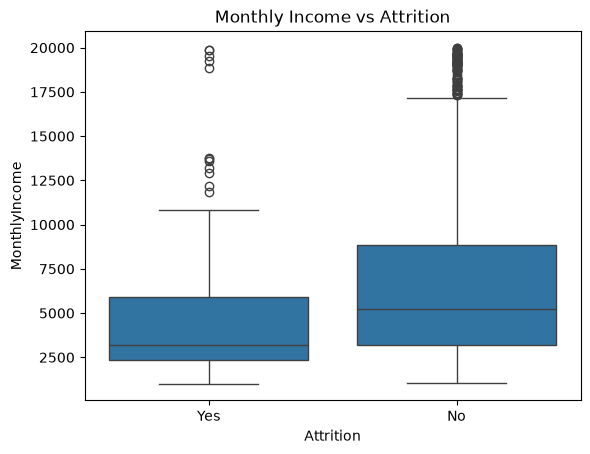

In [14]:
sns.boxplot(data=df, x="Attrition", y="MonthlyIncome")
plt.title("Monthly Income vs Attrition")
plt.show()

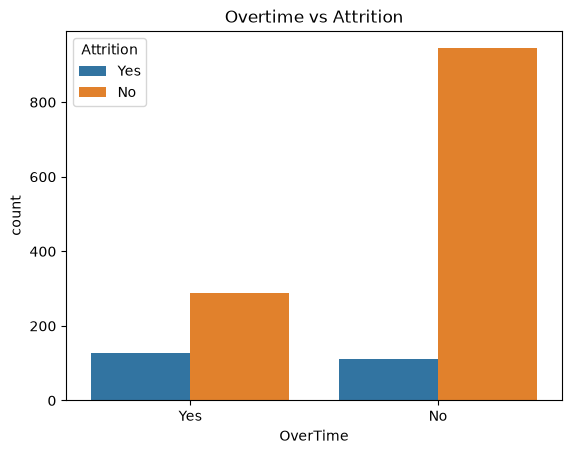

In [15]:
sns.countplot(data=df, x="OverTime", hue="Attrition")
plt.title("Overtime vs Attrition")
plt.show()

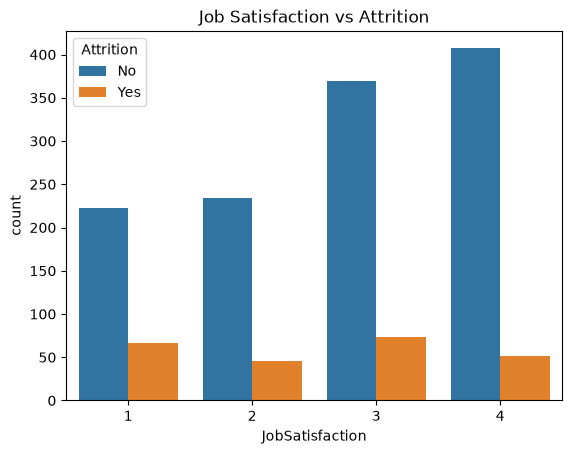

In [16]:
sns.countplot(data=df, x="JobSatisfaction", hue="Attrition")
plt.title("Job Satisfaction vs Attrition")
plt.show()

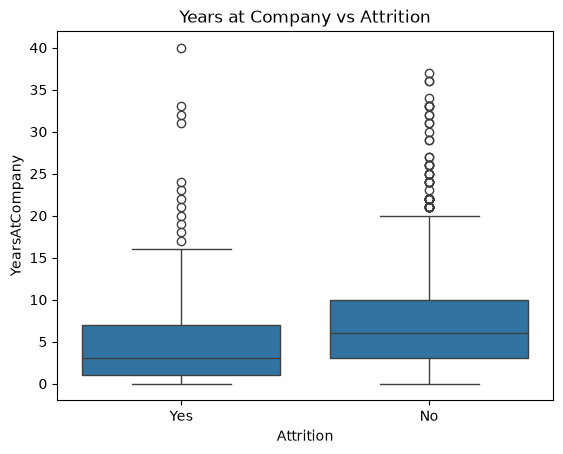

In [17]:
sns.boxplot(data=df, x="Attrition", y="YearsAtCompany")
plt.title("Years at Company vs Attrition")
plt.show()

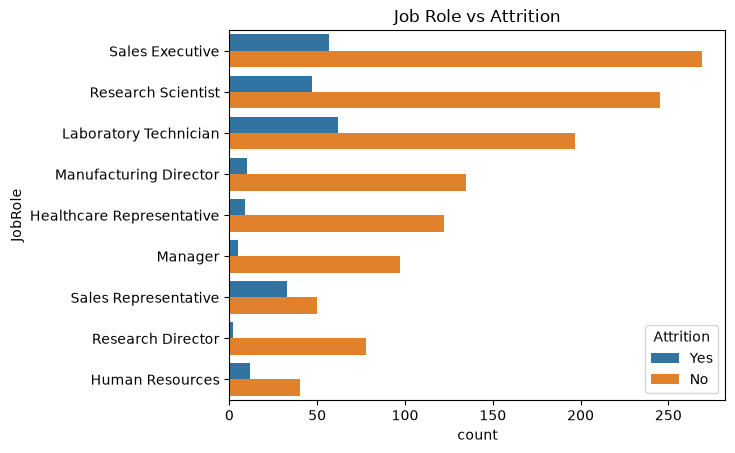

In [18]:
sns.countplot(data=df, y="JobRole", hue="Attrition")
plt.title("Job Role vs Attrition")
plt.show()

In [19]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSinceLastPromotion     0
YearsWithCurrManager        0
dtype: int64

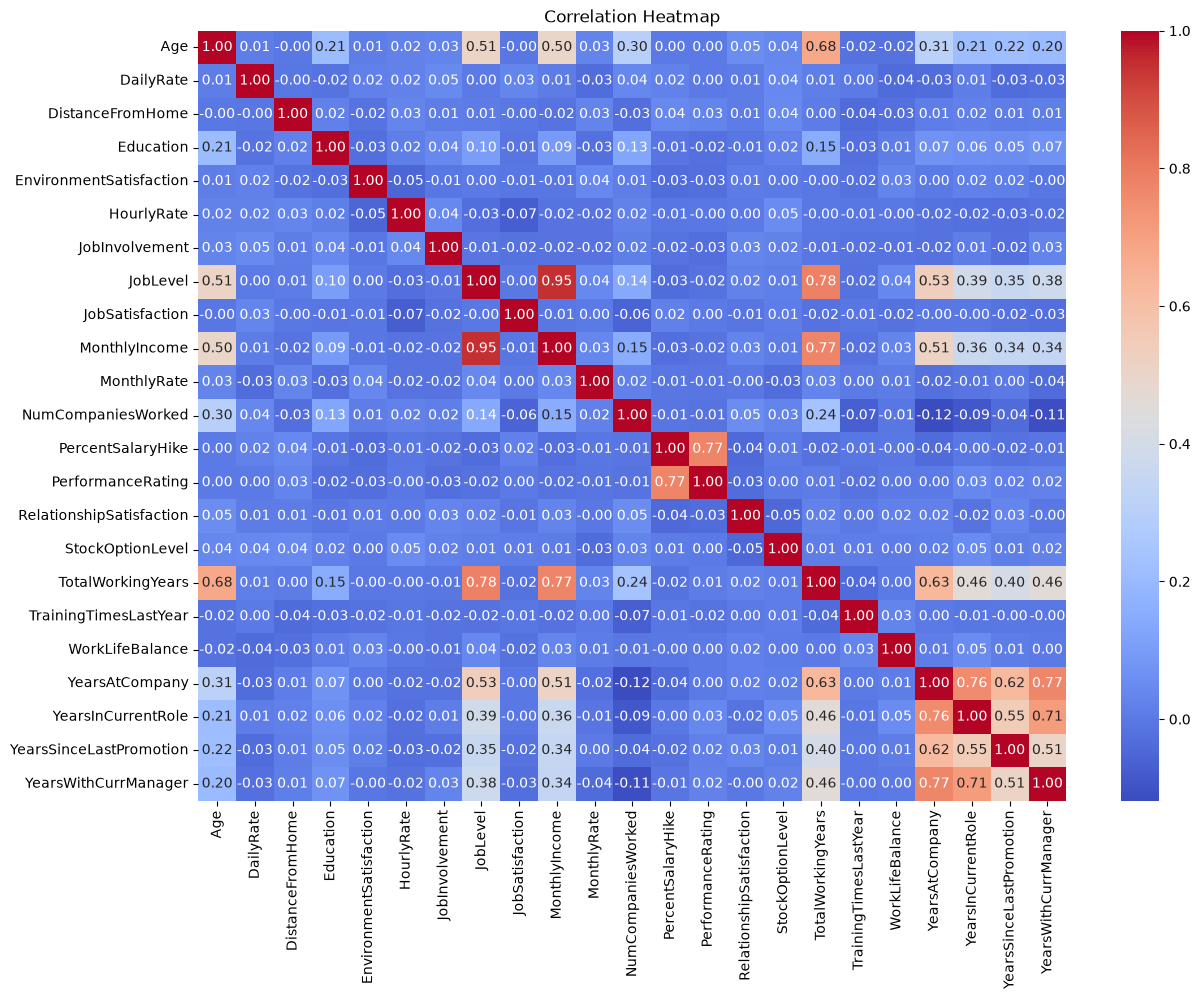

In [20]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [21]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSinceLastPromotion     0
YearsWithCurrManager        0
dtype: int64

In [22]:
df["Attrition"] = df["Attrition"].map({
    "No": 0,
    "Yes": 1
})

x = df.drop("Attrition", axis=1)
y = df["Attrition"]

x = pd.get_dummies(x, drop_first=True, dtype=int)

print(x.head())
print("Feature shape:", x.shape)

   Age  DailyRate  DistanceFromHome  Education  EnvironmentSatisfaction  \
0   41       1102                 1          2                        2   
1   49        279                 8          1                        3   
2   37       1373                 2          2                        4   
3   33       1392                 3          4                        4   
4   27        591                 2          1                        1   

   HourlyRate  JobInvolvement  JobLevel  JobSatisfaction  MonthlyIncome  ...  \
0          94               3         2                4           5993  ...   
1          61               2         2                2           5130  ...   
2          92               2         1                3           2090  ...   
3          56               3         1                3           2909  ...   
4          40               3         1                2           3468  ...   

   JobRole_Laboratory Technician  JobRole_Manager  \
0              

In [23]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", x_train.shape)
print("X_test:", x_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1176, 44)
X_test: (294, 44)
y_train: (1176,)
y_test: (294,)


## Feature scaling

In [24]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

## Logistic Regression

In [25]:
lr = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

lr.fit(x_train_scaled, y_train)

y_pred_lr = lr.predict(x_test_scaled)

print("Training accuracy:", lr.score(x_train_scaled, y_train))
print("Testing accuracy:", accuracy_score(y_test, y_pred_lr))

Training accuracy: 0.7976190476190477
Testing accuracy: 0.717687074829932


In [26]:
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["Stayed", "Left"],
    zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

      Stayed       0.92      0.74      0.82       255
        Left       0.26      0.59      0.36        39

    accuracy                           0.72       294
   macro avg       0.59      0.66      0.59       294
weighted avg       0.83      0.72      0.76       294



In [28]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm_lr)

Confusion Matrix:
[[188  67]
 [ 16  23]]


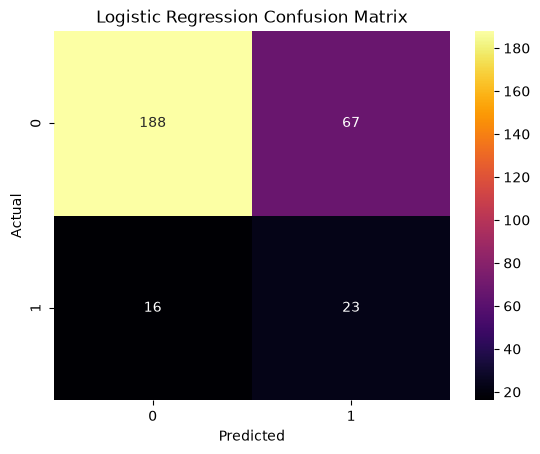

In [29]:
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="inferno")
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Decision Tree Classifier

In [30]:
dt = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

dt.fit(x_train, y_train)

y_pred_dt = dt.predict(x_test)

print("Training accuracy:", dt.score(x_train, y_train))
print("Testing accuracy:", accuracy_score(y_test, y_pred_dt))

Training accuracy: 1.0
Testing accuracy: 0.7857142857142857


In [31]:
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["Stayed", "Left"],
    zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

      Stayed       0.88      0.87      0.88       255
        Left       0.23      0.26      0.24        39

    accuracy                           0.79       294
   macro avg       0.56      0.56      0.56       294
weighted avg       0.80      0.79      0.79       294



In [32]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Confusion Matrix:")
print(cm_dt)

Confusion Matrix:
[[221  34]
 [ 29  10]]


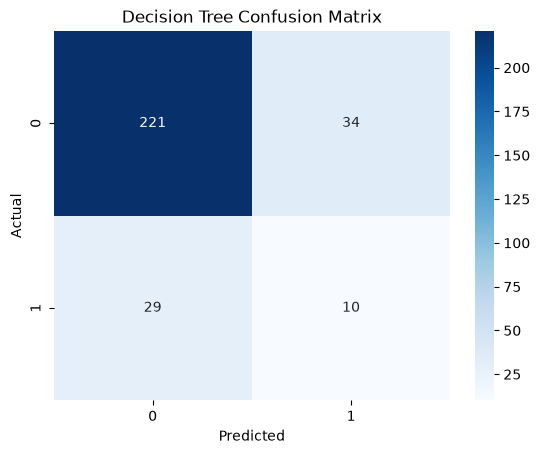

In [33]:
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Blues")
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Decision Tree visualization

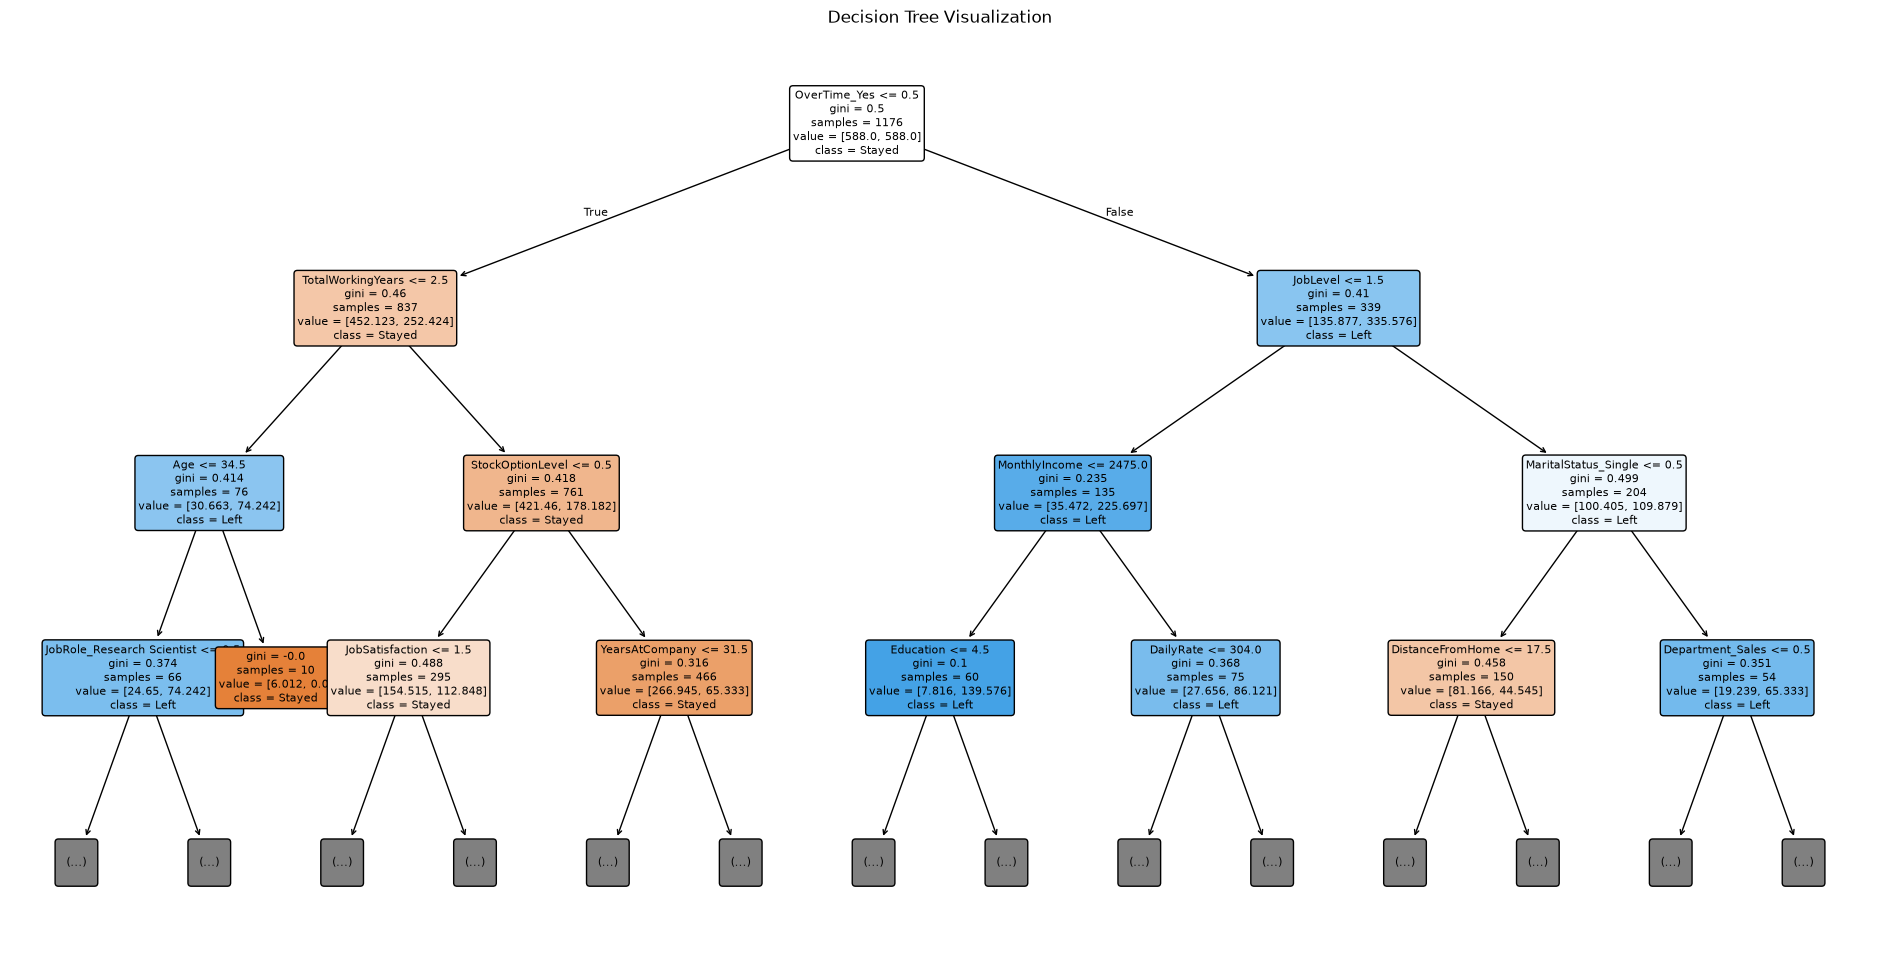

In [34]:
plt.figure(figsize=(24, 12))

plot_tree(
    dt,
    feature_names=x.columns,
    class_names=["Stayed", "Left"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Visualization")
plt.show()

## Decision Tree hyperparameter tuning

In [35]:
dt_params = {
    "max_depth": [3, 5, 7, 10, 15],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10]
}

In [36]:
dt_grid = GridSearchCV(
    DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    dt_params,
    scoring="recall",
    cv=5,
    n_jobs=-1
)

dt_grid.fit(x_train, y_train)

print("Best parameters:", dt_grid.best_params_)
print("Best CV recall:", dt_grid.best_score_)

Best parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5}
Best CV recall: 0.5706410256410257


In [37]:
best_dt = dt_grid.best_estimator_

y_pred_best_dt = best_dt.predict(x_test)

In [38]:
print(classification_report(
    y_test,
    y_pred_best_dt,
    target_names=["Stayed", "Left"],
    zero_division=0
))

              precision    recall  f1-score   support

      Stayed       0.90      0.83      0.86       255
        Left       0.27      0.41      0.32        39

    accuracy                           0.77       294
   macro avg       0.58      0.62      0.59       294
weighted avg       0.82      0.77      0.79       294



## Random Forest Classifier

In [39]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf.fit(x_train, y_train)

y_pred_rf = rf.predict(x_test)

print("Training accuracy:", rf.score(x_train, y_train))
print("Testing accuracy:", accuracy_score(y_test, y_pred_rf))

Training accuracy: 1.0
Testing accuracy: 0.8707482993197279


In [40]:
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Stayed", "Left"],
    zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

      Stayed       0.89      0.96      0.93       255
        Left       0.53      0.26      0.34        39

    accuracy                           0.87       294
   macro avg       0.71      0.61      0.64       294
weighted avg       0.85      0.87      0.85       294



In [41]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Confusion Matrix:")
print(cm_rf)

Confusion Matrix:
[[246   9]
 [ 29  10]]


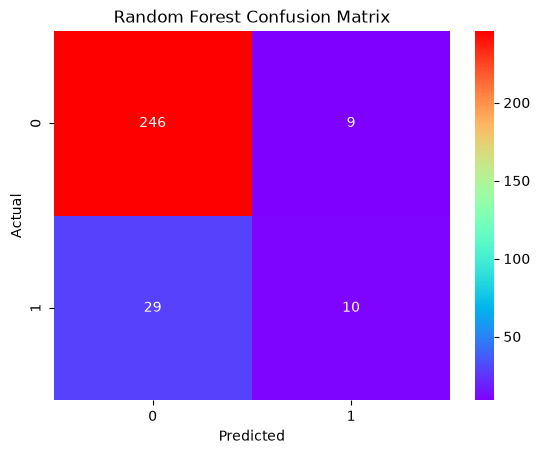

In [42]:
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="rainbow")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Random Forest hyperparameter tuning

In [43]:
rf_params = {
    "n_estimators": [50, 100, 200, 300],
    "max_depth": [5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

In [44]:
rf_grid = GridSearchCV(
    RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=1
    ),
    rf_params,
    scoring="recall",
    cv=5,
    n_jobs=-1
)

rf_grid.fit(x_train, y_train)
print("Best parameters:", rf_grid.best_params_)
print("Best CV recall:", rf_grid.best_score_)

Best parameters: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 50}
Best CV recall: 0.6362820512820513


In [45]:
best_rf = rf_grid.best_estimator_

y_pred_best_rf = best_rf.predict(x_test)

In [46]:
print(classification_report(
    y_test,
    y_pred_best_rf,
    target_names=["Stayed", "Left"],
    zero_division=0
))

              precision    recall  f1-score   support

      Stayed       0.92      0.85      0.89       255
        Left       0.35      0.51      0.42        39

    accuracy                           0.81       294
   macro avg       0.64      0.68      0.65       294
weighted avg       0.84      0.81      0.82       294



## Feature importance

Decision Tree Feature Importance:
OverTime_Yes                         0.255951
TotalWorkingYears                    0.109131
JobLevel                             0.098598
MaritalStatus_Single                 0.064106
DistanceFromHome                     0.062416
StockOptionLevel                     0.054606
JobSatisfaction                      0.050591
YearsAtCompany                       0.035428
DailyRate                            0.034827
JobInvolvement                       0.030510
MonthlyIncome                        0.027604
Department_Sales                     0.026971
MonthlyRate                          0.026852
Age                                  0.023163
Department_Research & Development    0.020902
dtype: float64


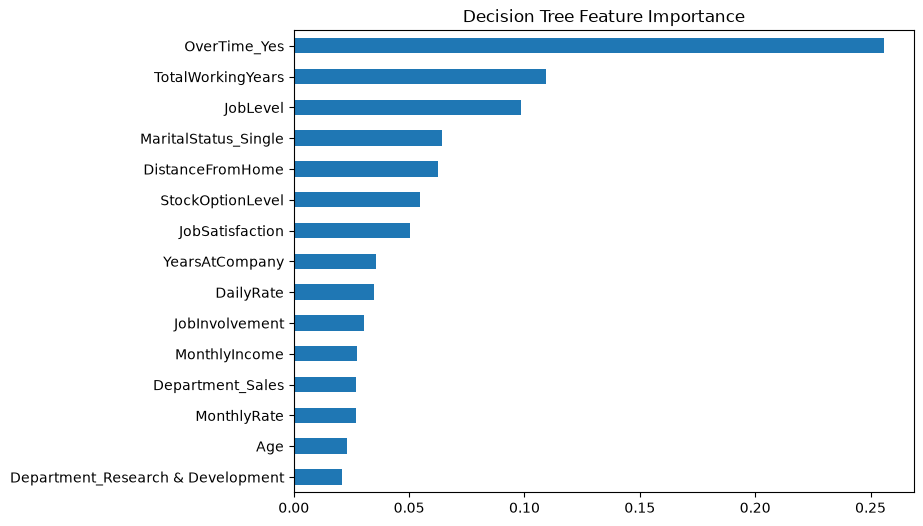

Random Forest Feature Importance:
OverTime_Yes            0.141568
MonthlyIncome           0.092990
StockOptionLevel        0.080661
Age                     0.066837
YearsAtCompany          0.059278
JobLevel                0.054900
TotalWorkingYears       0.045131
YearsInCurrentRole      0.042069
YearsWithCurrManager    0.040800
MaritalStatus_Single    0.039062
DailyRate               0.023220
NumCompaniesWorked      0.021375
MonthlyRate             0.021091
JobSatisfaction         0.019442
JobInvolvement          0.019251
dtype: float64


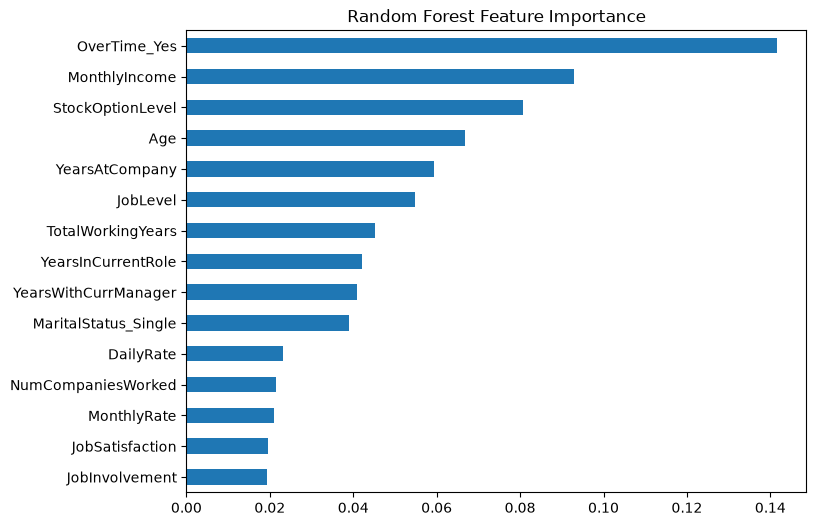

In [47]:
dt_importance = pd.Series(
    best_dt.feature_importances_,
    index=x.columns
).sort_values(ascending=False)

print("Decision Tree Feature Importance:")
print(dt_importance.head(15))

dt_importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.title("Decision Tree Feature Importance")
plt.show()


rf_importance = pd.Series(
    best_rf.feature_importances_,
    index=x.columns
).sort_values(ascending=False)

print("Random Forest Feature Importance:")
print(rf_importance.head(15))

rf_importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.title("Random Forest Feature Importance")
plt.show()

In [48]:
model_predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_best_dt,
    "Random Forest": y_pred_best_rf
}

model_objects = {
    "Logistic Regression": lr,
    "Decision Tree": best_dt,
    "Random Forest": best_rf
}

comparison = []

for name, pred in model_predictions.items():

    tn, fp, fn, tp = confusion_matrix(
        y_test, pred, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    comparison.append({
        "Model": name,
        "Training Accuracy": model_objects[name].score(
            x_train_scaled if name == "Logistic Regression" else x_train,
            y_train
        ),
        "Testing Accuracy": accuracy_score(y_test, pred),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "False Positives": fp,
        "False Negatives": fn
    })

comparison_df = pd.DataFrame(comparison)

display(
    comparison_df.sort_values(
        "Recall", ascending=False
    ).round(4)
)

,Model,Training Accuracy,Testing Accuracy,Precision,Recall,F1 Score,False Positives,False Negatives
0,Logistic Regression,0.7976,0.7177,0.2556,0.5897,0.3566,67,16
2,Random Forest,0.8733,0.8095,0.3509,0.5128,0.4167,37,19
1,Decision Tree,0.8673,0.7721,0.2667,0.4103,0.3232,44,23


In [49]:
new_employee = x.iloc[[0]].copy()

sample_values = {
    "Age": 28,
    "DistanceFromHome": 15,
    "JobSatisfaction": 2,
    "MonthlyIncome": 3000,
    "OverTime_Yes": 1,
    "TotalWorkingYears": 4,
    "YearsAtCompany": 2,
    "YearsInCurrentRole": 1,
    "YearsSinceLastPromotion": 1,
    "YearsWithCurrManager": 1,
    "WorkLifeBalance": 2
}

for col, value in sample_values.items():
    if col in new_employee.columns:
        new_employee.loc[:, col] = value

new_employee_scaled = scaler.transform(new_employee)

print("Logistic Regression:")
print(
    "Likely to leave"
    if lr.predict(new_employee_scaled)[0] == 1
    else "Likely to stay"
)

print("\nDecision Tree:")
print(
    "Likely to leave"
    if best_dt.predict(new_employee)[0] == 1
    else "Likely to stay"
)

print("\nRandom Forest:")
print(
    "Likely to leave"
    if best_rf.predict(new_employee)[0] == 1
    else "Likely to stay"
)

Logistic Regression:
Likely to leave

Decision Tree:
Likely to stay

Random Forest:
Likely to leave
